In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import os, sys
sys.path.append(os.path.dirname(os.path.abspath('')))
from src.environments.pendulum import Hamiltonian, double_pendulum_derivatives, transform_to_cartesian
from src.paths import get_results_dir
RESULTS_DIR, DATA_DIR = get_results_dir()

array([{'m1': 0.5, 'm2': 1.0, 'l1': 0.5, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.0, 'l1': 0.5, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.0, 'l1': 1.0, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.0, 'l1': 1.0, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.5, 'l1': 0.5, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.5, 'l1': 0.5, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.5, 'l1': 1.0, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.5, 'l1': 1.0, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.0, 'l1': 0.5, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.0, 'l1': 0.5, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.0, 'l1': 1.0, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.0, 'l1': 1.0, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.5, 'l1': 0.5, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.5, 'l1': 0.5, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.5, 'l1': 1.0, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.5, 'l1': 1.0, 'l2': 1.5}], dtype=object)

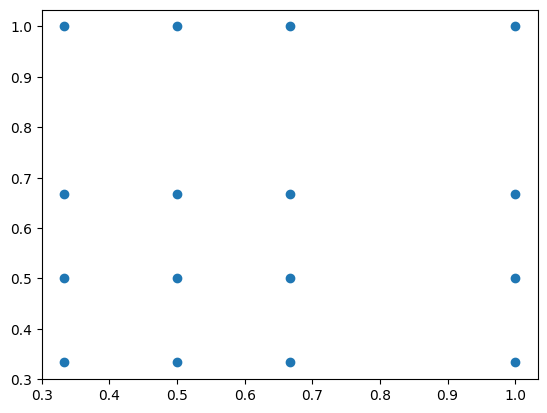

In [2]:
parameters = np.array([
    {"m1": m1, "m2": m2, "l1": l1, "l2": l2}
    for m1 in [0.5, 1.0]
    for m2 in [1.0, 1.5]
    for l1 in [0.5, 1.0]
    for l2 in [1.0, 1.5]
])
plt.scatter([parameters[i]["m1"] / parameters[i]["m2"] for i in range(len(parameters))],
            [parameters[i]["l1"] / parameters[i]["l2"] for i in range(len(parameters))])
parameters

In [12]:
def initial_conditions_for_all_configs(
    target_energies,
    params_array,
    theta1=np.pi,
    theta2=np.pi,
    direction=(1.0, -1.0),
    g=9.81,
):
    """
    Given a target total energy, return [theta1, omega1, theta2, omega2]
    for each configuration in params_array so all start at that energy.
    """
    d1, d2 = direction
    cos_delta = np.cos(theta1 - theta2)

    all_ics = []
    energies = []

    for k, p in enumerate(params_array):
        m1 = p["m1"]
        m2 = p["m2"]
        l1 = p["l1"]
        l2 = p["l2"]
        target_energy = target_energies[k]

        potential = -(m1 + m2) * g * l1 * np.cos(theta1) - m2 * g * l2 * np.cos(theta2)
        kinetic_coeff = 0.5 * m1 * (l1 * d1) ** 2 + 0.5 * m2 * (
            (l1 * d1) ** 2 + (l2 * d2) ** 2 + 2.0 * l1 * l2 * d1 * d2 * cos_delta
        )

        if target_energy < potential:
            raise ValueError(
                f"target_energy={target_energy:.6f} is below potential={potential:.6f} for params={p}"
            )
        if kinetic_coeff <= 0:
            raise ValueError(f"Non-positive kinetic coefficient for params={p}, direction={direction}")

        scale = np.sqrt((target_energy - potential) / kinetic_coeff)
        omega1 = scale * d1
        omega2 = scale * d2

        ic = np.array([theta1, omega1, theta2, omega2], dtype=np.float32)
        all_ics.append(ic)

        traj0 = np.array([
            np.sin(theta1),
            np.cos(theta1),
            np.sin(theta2),
            np.cos(theta2),
            omega1,
            omega2,
        ], dtype=np.float32)
        e0, _, _ = Hamiltonian(traj0, p, g=g)

        assert np.abs(e0 - target_energy)<0.5
    all_ics = np.stack(all_ics, axis=0)



    return all_ics

initial_conditions_per_config = initial_conditions_for_all_configs(
    target_energies=[20.0]*16,
    params_array=parameters,
    theta1=np.pi-1.5,
    theta2=np.pi-1.5,
    direction=(1.0, -2.0),
)

In [ ]:
# integrate
from matplotlib.animation import FuncAnimation
g = 9.81
dt = 0.01


t = np.arange(500) * dt
for subject_idx, args in enumerate(parameters):
    initial_conditions = initial_conditions_per_config[subject_idx]
    solution = odeint(double_pendulum_derivatives, initial_conditions, t, args=(args["m1"], args["m2"], args["l1"], args["l2"], g))
    
    # make video of the solution
    fig, ax = plt.subplots()
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    line, = ax.plot([], [], 'o-', lw=2)
    def init():
        line.set_data([], [])
        return line,
    def update(frame):  
        x1 = args["l1"] * np.sin(solution[frame, 0])
        y1 = -args["l1"] * np.cos(solution[frame, 0])
        x2 = x1 + args["l2"] * np.sin(solution[frame, 2])
        y2 = y1 - args["l2"] * np.cos(solution[frame, 2])
        line.set_data([0, x1, x2], [0, y1, y2])
        return line,
    ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True)
    plt.show()
    # save animation
    ani.save(f'double_pendulum_{args["m1"]}_{args["m2"]}_{args["l1"]}_{args["l2"]}.mp4', writer='ffmpeg', fps=int(round(1 / dt)))

## Same Energies

In [ ]:
import os
import pickle

# gravity 
g = 9.81

# generation settings
n_subjects = len(parameters)
n_steps = 10000
dt = 0.01
t = np.arange(n_steps) * dt
seq_len = 275  # keeps 20 segments per subject, analogous to hier-lorenz chunking

assert n_subjects == 16, f"Expected 16 parameter sets, found {n_subjects}."
#assert n_steps % seq_len == 0, "seq_len must divide n_steps exactly."

# deterministic RNG for reproducibility
rng = np.random.default_rng(0)

# final representation per time step:
# [sin(theta1), cos(theta1), sin(theta2), cos(theta2), omega1, omega2]
noisy = np.empty((n_subjects, n_steps, 6), dtype=np.float32)

initial_conditions_per_config = initial_conditions_for_all_configs(
    target_energies=[20.0]*16,
    params_array=parameters,
    theta1=np.pi-1.5,
    theta2=np.pi-1.5,
    direction=(1.0, -2.0),
)

for subject_idx, p in enumerate(parameters):
    initial_conditions = initial_conditions_per_config[subject_idx]
    sol = odeint(
        double_pendulum_derivatives,
        initial_conditions,
        t,
        args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
    ).astype(np.float32)

    theta1 = sol[:, 0]
    omega1 = sol[:, 1]
    theta2 = sol[:, 2]
    omega2 = sol[:, 3]

    state = np.stack(
        [
            np.sin(theta1),
            np.cos(theta1),
            np.sin(theta2),
            np.cos(theta2),
            omega1,
            omega2,
        ],
        axis=-1,
    ).astype(np.float32)

    noisy[subject_idx] = state

    # subject-specific, per-dimension noise variance = 5% of per-dimension data variance
    subject_var = np.var(state, axis=0)  # shape: (6,)
    noise_std = np.sqrt(0.005 * subject_var).astype(np.float32)
    noise = rng.normal(0.0, 1.0, size=state.shape).astype(np.float32) * noise_std
    noisy[subject_idx] = state + noise

print("noisy shape:", noisy.shape)

# full is the same as noisy, but without noise and with 100000 steps instead of 5500 and with different initial conditions
full = np.empty((n_subjects, 100000, 6), dtype=np.float32)
initial_conditions_per_config = initial_conditions_for_all_configs(
    target_energy=20.0,
    params_array=parameters,
    theta1=np.pi-1.6,
    theta2=np.pi-1.6,
    direction=(1.0, -2.0),
)
for subject_idx, p in enumerate(parameters):
    initial_conditions = initial_conditions_per_config[subject_idx]
    sol = odeint(
        double_pendulum_derivatives,
        initial_conditions,
        np.arange(100000) * dt,
        args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
    ).astype(np.float32)

    theta1 = sol[:, 0]
    omega1 = sol[:, 1]
    theta2 = sol[:, 2]
    omega2 = sol[:, 3]

    state = np.stack(
        [
            np.sin(theta1),
            np.cos(theta1),
            np.sin(theta2),
            np.cos(theta2),
            omega1,
            omega2,
        ],
        axis=-1,
    ).astype(np.float32)
    
    full[subject_idx] = state

print("full shape:", full.shape)

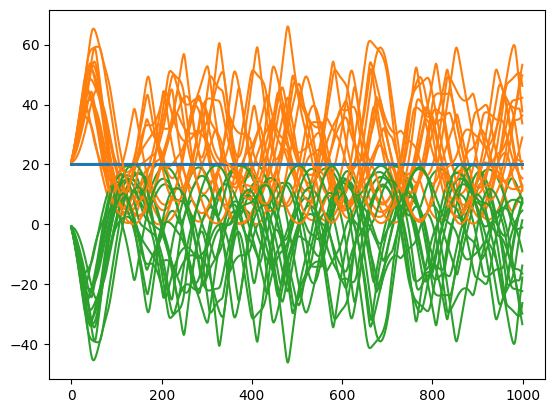

In [7]:
for i in range(16):
    energy, kin_energy, pot_energy = Hamiltonian(full[i][:1000], params=parameters[i])
    plt.plot(energy, c="C0")
    plt.plot(kin_energy, c="C1")
    plt.plot(pot_energy, c="C2")

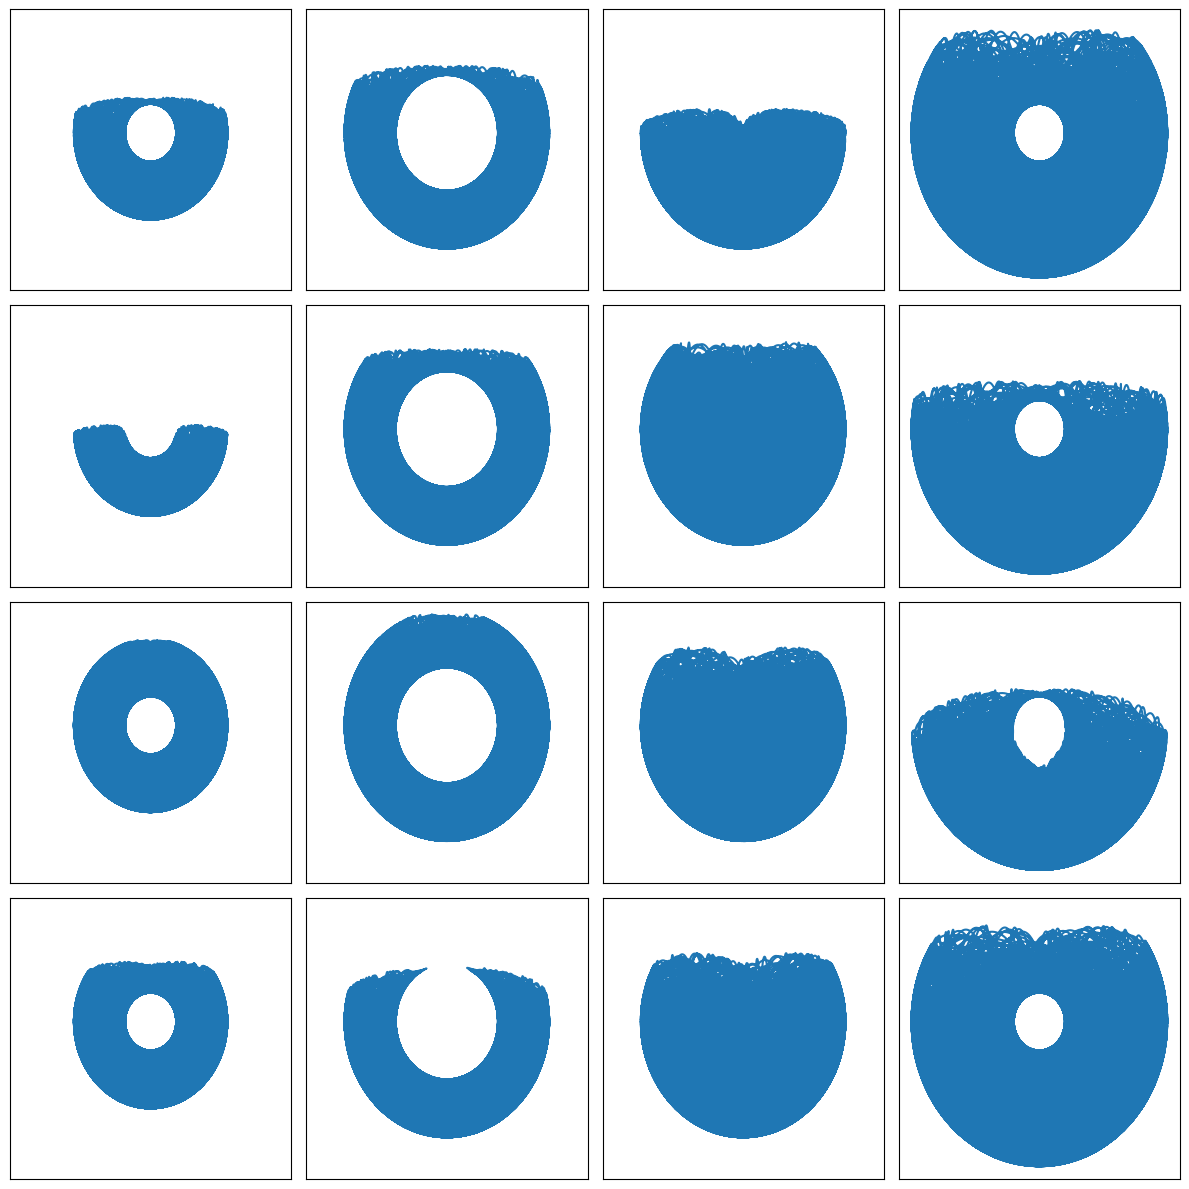

In [44]:
# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)

fig, axs = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for i in range(16):
    ax = axs[i // 4, i % 4]
    
    full_cartesian = transform_to_cartesian(full[i], parameters = parameters[i])
    
    # Plot data
    ax.plot(full_cartesian[:, 2], full_cartesian[:, 3])

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()

## Saving

In [ ]:
# save global arrays (analogous to hier-lorenz full/noisy/params files)
dataset_dir = DATA_DIR + "/multi_task_double_pendulum/default_20_joule"
os.makedirs(dataset_dir, exist_ok=True)
np.save(os.path.join(dataset_dir, "full.npy"), full)
np.save(os.path.join(dataset_dir, "noisy.npy"), noisy)
np.save(os.path.join(dataset_dir, "params.npy"), parameters, allow_pickle=True)

# save chunked observations per subject (analogous to hier-lorenz_preprocessed layout)
preprocessed_dir = DATA_DIR + "/double-pendulum_preprocessed_20_joule"
for subject_idx in range(n_subjects):
    subject_save_path = os.path.join(preprocessed_dir, str(subject_idx), "observations")
    os.makedirs(subject_save_path, exist_ok=True)

    chunks = [
        noisy[subject_idx, i * seq_len:(i + 1) * seq_len]
        for i in range(n_steps // seq_len)
    ]
    with open(os.path.join(subject_save_path, "noisy.pkl"), "wb") as f:
        pickle.dump(chunks, f)

## Individual Energy Levels per Subject

In [35]:
#energy_levels = np.random.rand(20)*40-20
energy_levels = np.array([ 12.26416801,  -3.6694082 ,   6.94238879,  15.34266695,
         5.83245144,   2.91877493,   1.69040673,  -3.87149322,
         2.98827165,  -5.53008167,  12.52108342,  16.13409483,
        13.7864781 , -17.354703  , -10.82176862,  14.44611178,
         9.76581025, -17.3183169 , -18.03506957,  -5.30514053])
energy_levels

array([ 12.26416801,  -3.6694082 ,   6.94238879,  15.34266695,
         5.83245144,   2.91877493,   1.69040673,  -3.87149322,
         2.98827165,  -5.53008167,  12.52108342,  16.13409483,
        13.7864781 , -17.354703  , -10.82176862,  14.44611178,
         9.76581025, -17.3183169 , -18.03506957,  -5.30514053])

In [13]:
import os
import pickle
# gravity 
g = 9.81

# generation settings
n_subjects = len(parameters)
n_steps = 10000
dt = 0.01
t = np.arange(n_steps) * dt
seq_len = 275  # keeps 20 segments per subject, analogous to hier-lorenz chunking

assert n_subjects == 16, f"Expected 16 parameter sets, found {n_subjects}."
#assert n_steps % seq_len == 0, "seq_len must divide n_steps exactly."

# deterministic RNG for reproducibility
rng = np.random.default_rng(0)

# final representation per time step:
# [sin(theta1), cos(theta1), sin(theta2), cos(theta2), omega1, omega2]
noisy = np.empty((n_subjects, n_steps, 6), dtype=np.float32)
initial_conditions_per_config = initial_conditions_for_all_configs(
    target_energies=energy_levels,
    params_array=parameters,
    theta1=np.pi-3,
    theta2=np.pi-3,
    direction=(1.0, -2.0),
    )
for subject_idx, p in enumerate(parameters):
    initial_conditions = initial_conditions_per_config[subject_idx]
    sol = odeint(
        double_pendulum_derivatives,
        initial_conditions,
        t,
        args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
    ).astype(np.float32)

    theta1 = sol[:, 0]
    omega1 = sol[:, 1]
    theta2 = sol[:, 2]
    omega2 = sol[:, 3]

    state = np.stack(
        [
            np.sin(theta1),
            np.cos(theta1),
            np.sin(theta2),
            np.cos(theta2),
            omega1,
            omega2,
        ],
        axis=-1,
    ).astype(np.float32)

    noisy[subject_idx] = state

    # subject-specific, per-dimension noise variance = 5% of per-dimension data variance
    subject_var = np.var(state, axis=0)  # shape: (6,)
    noise_std = np.sqrt(0.005 * subject_var).astype(np.float32)
    noise = rng.normal(0.0, 1.0, size=state.shape).astype(np.float32) * noise_std
    noisy[subject_idx] = state + noise

print("noisy shape:", noisy.shape)

# full is the same as noisy, but without noise and with 100000 steps instead of 5500 and with different initial conditions
full = np.empty((n_subjects, 100000, 6), dtype=np.float32)
initial_conditions_per_config = initial_conditions_for_all_configs(
    target_energies=energy_levels,
    params_array=parameters,
    theta1=np.pi-2.9,
    theta2=np.pi-2.9,
    direction=(1.0, -2.0),
    )
for subject_idx, p in enumerate(parameters):
    initial_conditions = initial_conditions_per_config[subject_idx]
    sol = odeint(
        double_pendulum_derivatives,
        initial_conditions,
        np.arange(100000) * dt,
        args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
    ).astype(np.float32)

    theta1 = sol[:, 0]
    omega1 = sol[:, 1]
    theta2 = sol[:, 2]
    omega2 = sol[:, 3]

    state = np.stack(
        [
            np.sin(theta1),
            np.cos(theta1),
            np.sin(theta2),
            np.cos(theta2),
            omega1,
            omega2,
        ],
        axis=-1,
    ).astype(np.float32)
    
    full[subject_idx] = state

print("full shape:", full.shape)
    

noisy shape: (16, 10000, 6)
full shape: (16, 100000, 6)


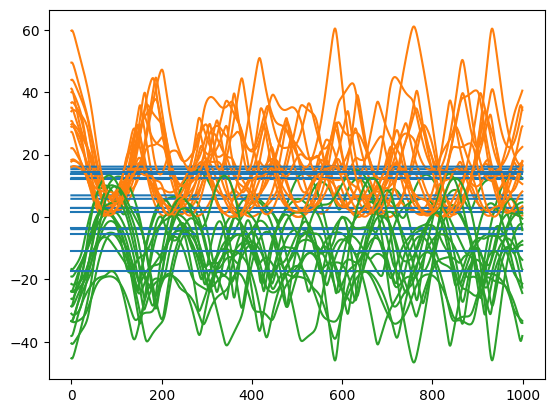

In [14]:
for i in range(16):
    energy, kin_energy, pot_energy = Hamiltonian(full[i][:1000], params=parameters[i])
    plt.plot(energy, c="C0")
    plt.plot(kin_energy, c="C1")
    plt.plot(pot_energy, c="C2")

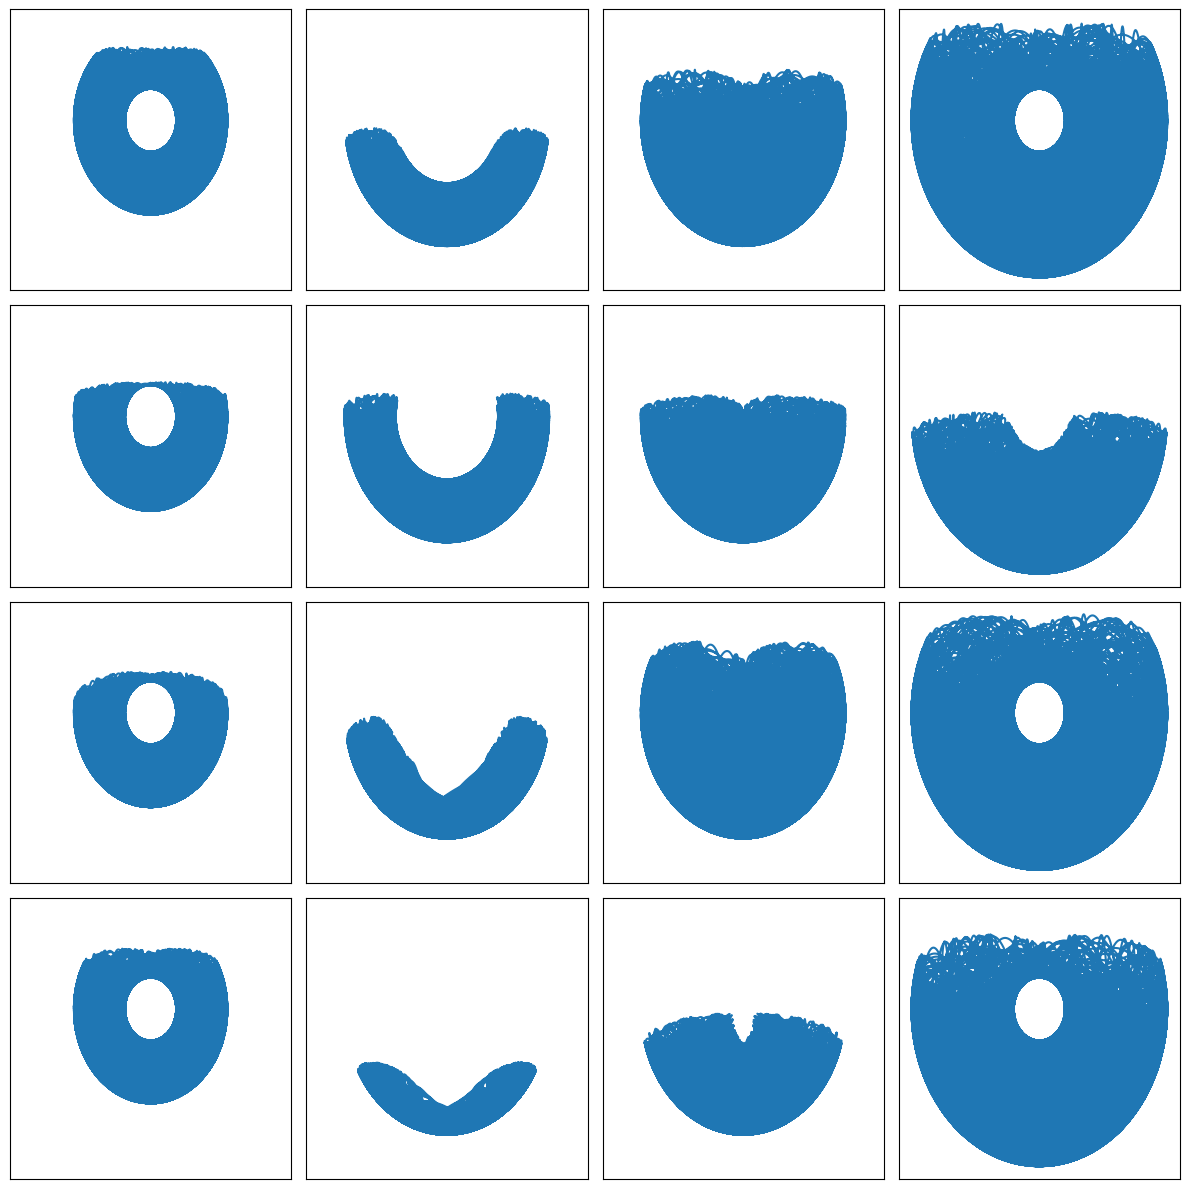

In [15]:
# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)

fig, axs = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for i in range(16):
    ax = axs[i // 4, i % 4]
    
    full_cartesian = transform_to_cartesian(full[i], parameters = parameters[i])
    
    # Plot data
    ax.plot(full_cartesian[:, 2], full_cartesian[:, 3])

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()

## Saving

In [ ]:
# save global arrays (analogous to hier-lorenz full/noisy/params files)
dataset_dir = DATA_DIR + "/multi_task_double_pendulum/default_levels"
os.makedirs(dataset_dir, exist_ok=True)
np.save(os.path.join(dataset_dir, "full.npy"), full)
np.save(os.path.join(dataset_dir, "noisy.npy"), noisy)
np.save(os.path.join(dataset_dir, "params.npy"), parameters, allow_pickle=True)

# save chunked observations per subject (analogous to hier-lorenz_preprocessed layout)
preprocessed_dir = DATA_DIR + "/double-pendulum_preprocessed_levels"
for subject_idx in range(n_subjects):
    subject_save_path = os.path.join(preprocessed_dir, str(subject_idx), "observations")
    os.makedirs(subject_save_path, exist_ok=True)

    chunks = [
        noisy[subject_idx, i * seq_len:(i + 1) * seq_len]
        for i in range(n_steps // seq_len)
    ]
    with open(os.path.join(subject_save_path, "noisy.pkl"), "wb") as f:
        pickle.dump(chunks, f)

## No Energy Levels

In [9]:
import os
import pickle
# gravity 
g = 9.81

# generation settings
n_subjects = len(parameters)
n_steps = 10000
dt = 0.01
t = np.arange(n_steps) * dt
seq_len = 200  

assert n_subjects == 16, f"Expected 16 parameter sets, found {n_subjects}."
#assert n_steps % seq_len == 0, "seq_len must divide n_steps exactly."

# deterministic RNG for reproducibility
rng = np.random.default_rng(0)

# final representation per time step:
# [sin(theta1), cos(theta1), sin(theta2), cos(theta2), omega1, omega2]
noisy = np.empty((n_subjects, n_steps // seq_len, seq_len, 6), dtype=np.float32)

for subject_idx, p in enumerate(parameters):
    for seq_idx in range(n_steps // seq_len):
        
        if seq_idx == 0:
            # the first time series should match the energy of the upper equilibrium point
            target_energy = Hamiltonian(np.array([0.0, -1, 0.0, -1, 0.0, 0.0]), params=p)[0]
            initial_condition = initial_conditions_for_all_configs(
                target_energies=np.array([target_energy]),
                params_array=np.array([p]),
                theta1=np.pi-3,
                theta2=np.pi-3,
                direction=(1.0, -2.0),
                )[0]
        else:
            initial_condition = [rng.uniform(0, 2*np.pi), rng.uniform(-5, 5), rng.uniform(0, 2*np.pi), rng.uniform(-5, 5)]
        
        sol = odeint(
            double_pendulum_derivatives,
            initial_condition,
            np.arange(seq_len) * dt,
            args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
        ).astype(np.float32)

        theta1 = sol[:, 0]
        omega1 = sol[:, 1]
        theta2 = sol[:, 2]
        omega2 = sol[:, 3]

        state = np.stack(
            [
                np.sin(theta1),
                np.cos(theta1),
                np.sin(theta2),
                np.cos(theta2),
                omega1,
                omega2,
            ],
            axis=-1,
        ).astype(np.float32)
    
        # subject-specific, per-dimension noise variance = 5% of per-dimension data variance
        subject_var = np.var(state, axis=0)  # shape: (6,)
        noise_std = np.sqrt(0.005 * subject_var).astype(np.float32)
        noise = rng.normal(0.0, 1.0, size=state.shape).astype(np.float32) * noise_std
        noisy[subject_idx, seq_idx] = state + noise

print("noisy shape:", noisy.shape)

# full is the same as noisy, but without noise and with 100000 steps instead of 5500 and with different initial conditions
full = np.empty((n_subjects, n_steps // seq_len, 10000, 6), dtype=np.float32)
for subject_idx, p in enumerate(parameters):
    for seq_idx in range(n_steps // seq_len):
        if seq_idx == 0:
            target_energy = Hamiltonian(np.array([0.0, -1, 0.0, -1, 0.0, 0.0]), params=p)[0]
            initial_condition = initial_conditions_for_all_configs(
                target_energies=np.array([target_energy]),
                params_array=np.array([p]),
                theta1=np.pi-3,
                theta2=np.pi-3,
                direction=(1.0, 2.0),
                )[0]
        else:
            initial_condition = [rng.uniform(0, 2*np.pi), rng.uniform(-5, 5), rng.uniform(0, 2*np.pi), rng.uniform(-5, 5)]
            
        sol = odeint(
            double_pendulum_derivatives,
            initial_condition,
            np.arange(10000) * dt,
            args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
        ).astype(np.float32)

        theta1 = sol[:, 0]
        omega1 = sol[:, 1]
        theta2 = sol[:, 2]
        omega2 = sol[:, 3]

        state = np.stack(
            [
                np.sin(theta1),
                np.cos(theta1),
                np.sin(theta2),
                np.cos(theta2),
                omega1,
                omega2,
            ],
            axis=-1,
        ).astype(np.float32)
        
        full[subject_idx, seq_idx] = state

print("full shape:", full.shape)
    

noisy shape: (16, 50, 200, 6)
full shape: (16, 50, 10000, 6)


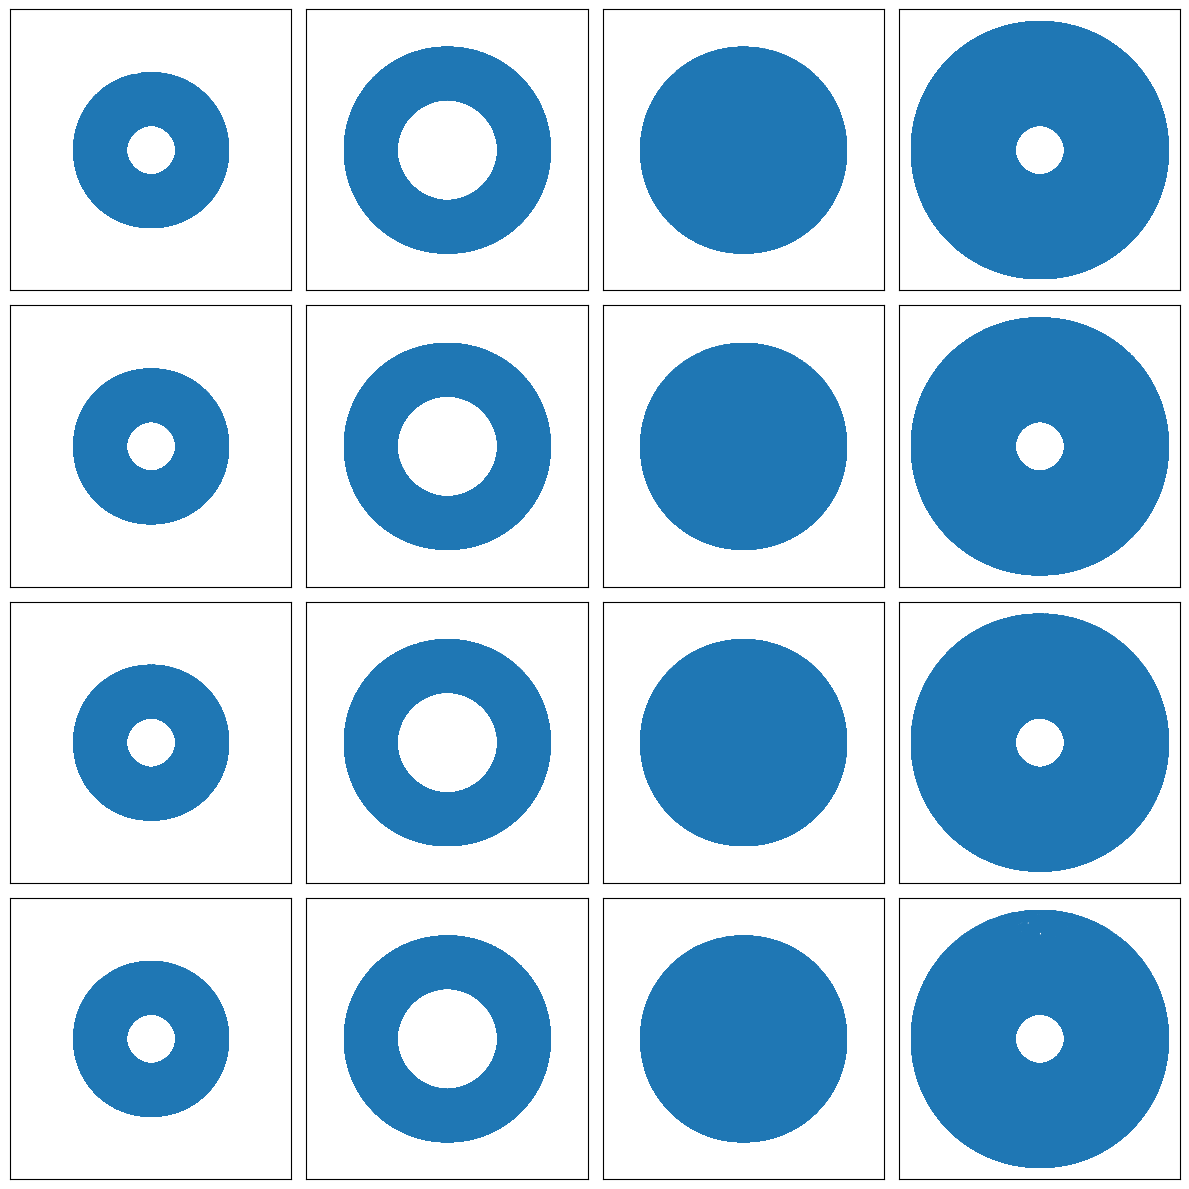

In [12]:
# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)

fig, axs = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for i in range(16):
    ax = axs[i // 4, i % 4]
    
    full_cartesian = transform_to_cartesian(full[i][:].reshape(-1, 6), parameters = parameters[i])
    # Plot data
    ax.scatter(full_cartesian[:, 2], full_cartesian[:, 3], s=1)

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()

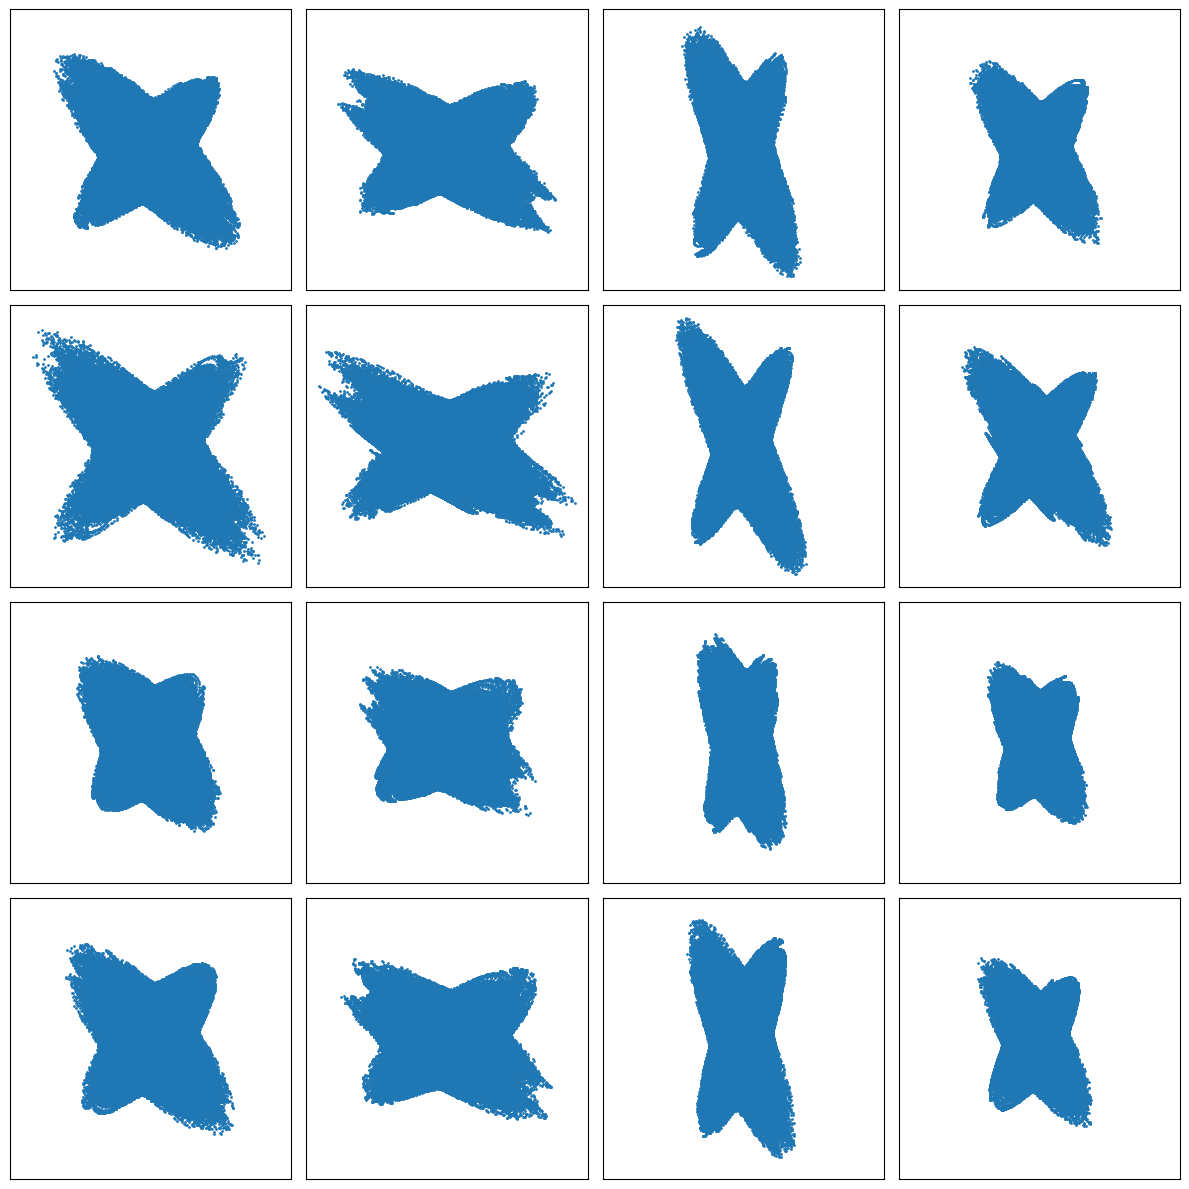

In [13]:
# Define shared limits
xlim = (-2, 1)
ylim = (-2, 4)

fig, axs = plt.subplots(4, 4, figsize=(12, 12), sharex=True, sharey=True)
for i in range(16):
    ax = axs[i // 4, i % 4]
    
    full_velocities = full[i][:, :, -2:].reshape(-1, 2)
    
    # Plot data
    ax.scatter(full_velocities[:, 0], full_velocities[:, 1], s=1)

    # Remove tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # Optionally remove ticks entirely:
    ax.set_xticks([])
    ax.set_yticks([])

plt.subplots_adjust(wspace=-0.5, hspace=-0.7, right=1, left=0, top=1, bottom=0)
plt.tight_layout()
plt.show()

### Saving

In [ ]:
# save global arrays (analogous to hier-lorenz full/noisy/params files)
dataset_dir = DATA_DIR + "/multi_task_double_pendulum/default"
os.makedirs(dataset_dir, exist_ok=True)
np.save(os.path.join(dataset_dir, "full.npy"), full)
np.save(os.path.join(dataset_dir, "noisy.npy"), noisy)
np.save(os.path.join(dataset_dir, "params.npy"), parameters, allow_pickle=True)

# save chunked observations per subject (analogous to hier-lorenz_preprocessed layout)
preprocessed_dir = DATA_DIR + "/double-pendulum_preprocessed"
for subject_idx in range(n_subjects):
    subject_save_path = os.path.join(preprocessed_dir, str(subject_idx), "observations")
    os.makedirs(subject_save_path, exist_ok=True)

    chunks = [
        noisy[subject_idx, i]
        for i in range(n_steps // seq_len)
    ]
    with open(os.path.join(subject_save_path, "noisy.pkl"), "wb") as f:
        pickle.dump(chunks, f)

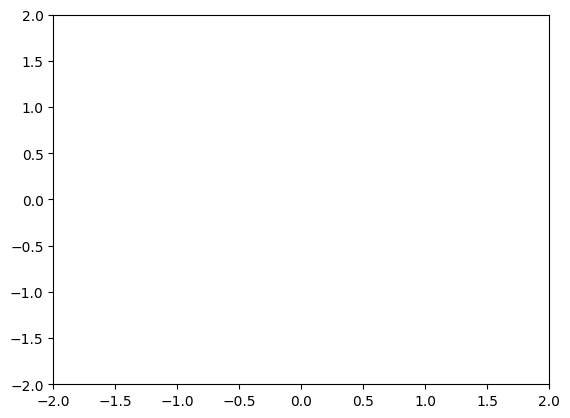

In [53]:
fig, ax = plt.subplots()
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
line, = ax.plot([], [], 'o-', lw=2)
def init():
    line.set_data([], [])
    return line,
def update(frame):  
    x1 = args["l1"] * np.sin(sol[frame, 0])
    y1 = -args["l1"] * np.cos(sol[frame, 0])
    x2 = x1 + args["l2"] * np.sin(sol[frame, 2])
    y2 = y1 - args["l2"] * np.cos(sol[frame, 2])
    line.set_data([0, x1, x2], [0, y1, y2])
    return line,
ani = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True)
plt.show()
# save animation
ani.save(f'__double_pendulum_{args["m1"]}_{args["m2"]}_{args["l1"]}_{args["l2"]}.mp4', writer='ffmpeg', fps=int(round(1 / dt)))

## Fine Tuning

array([{'m1': 0.5, 'm2': 1.0, 'l1': 0.5, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.0, 'l1': 0.5, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.0, 'l1': 1.0, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.0, 'l1': 1.0, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.5, 'l1': 0.5, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.5, 'l1': 0.5, 'l2': 1.5},
       {'m1': 0.5, 'm2': 1.5, 'l1': 1.0, 'l2': 1.0},
       {'m1': 0.5, 'm2': 1.5, 'l1': 1.0, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.0, 'l1': 0.5, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.0, 'l1': 0.5, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.0, 'l1': 1.0, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.0, 'l1': 1.0, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.5, 'l1': 0.5, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.5, 'l1': 0.5, 'l2': 1.5},
       {'m1': 1.0, 'm2': 1.5, 'l1': 1.0, 'l2': 1.0},
       {'m1': 1.0, 'm2': 1.5, 'l1': 1.0, 'l2': 1.5}], dtype=object)

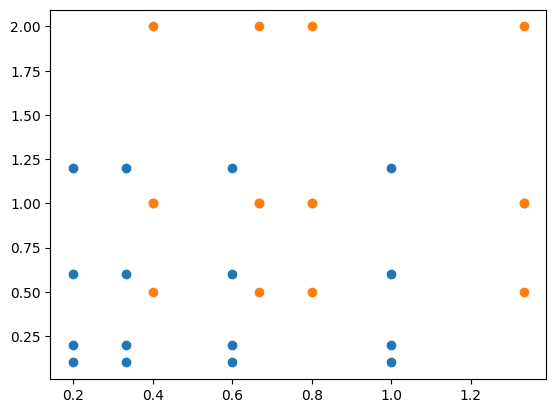

In [3]:
parameters_ft = np.array([{"m1": m1-0.25, "m2": m2-0.25, "l1": l1-0.4, "l2": l2-0.5} for m1 in [0.5, 1.0] for m2 in [1.0, 1.5] for l1 in [0.5, 1.0] for l2 in [1.0, 1.5]])
plt.scatter([parameters_ft[i]["m1"] / parameters_ft[i]["m2"] for i in range(len(parameters_ft))],
            [parameters_ft[i]["l1"] / parameters_ft[i]["l2"] for i in range(len(parameters_ft))])
plt.scatter([parameters[i]["m1"] / parameters_ft[i]["m2"] for i in range(len(parameters))],
            [parameters[i]["l1"] / parameters_ft[i]["l2"] for i in range(len(parameters))])
parameters

In [6]:
parameters_ft

array([{'m1': 0.25, 'm2': 0.75, 'l1': 0.09999999999999998, 'l2': 0.5},
       {'m1': 0.25, 'm2': 0.75, 'l1': 0.09999999999999998, 'l2': 1.0},
       {'m1': 0.25, 'm2': 0.75, 'l1': 0.6, 'l2': 0.5},
       {'m1': 0.25, 'm2': 0.75, 'l1': 0.6, 'l2': 1.0},
       {'m1': 0.25, 'm2': 1.25, 'l1': 0.09999999999999998, 'l2': 0.5},
       {'m1': 0.25, 'm2': 1.25, 'l1': 0.09999999999999998, 'l2': 1.0},
       {'m1': 0.25, 'm2': 1.25, 'l1': 0.6, 'l2': 0.5},
       {'m1': 0.25, 'm2': 1.25, 'l1': 0.6, 'l2': 1.0},
       {'m1': 0.75, 'm2': 0.75, 'l1': 0.09999999999999998, 'l2': 0.5},
       {'m1': 0.75, 'm2': 0.75, 'l1': 0.09999999999999998, 'l2': 1.0},
       {'m1': 0.75, 'm2': 0.75, 'l1': 0.6, 'l2': 0.5},
       {'m1': 0.75, 'm2': 0.75, 'l1': 0.6, 'l2': 1.0},
       {'m1': 0.75, 'm2': 1.25, 'l1': 0.09999999999999998, 'l2': 0.5},
       {'m1': 0.75, 'm2': 1.25, 'l1': 0.09999999999999998, 'l2': 1.0},
       {'m1': 0.75, 'm2': 1.25, 'l1': 0.6, 'l2': 0.5},
       {'m1': 0.75, 'm2': 1.25, 'l1': 0.6, 'l2'

In [34]:
import os
import pickle
# gravity 
g = 9.81

# generation settings
n_subjects = len(parameters_ft)
n_steps = 10000
dt = 0.01
t = np.arange(n_steps) * dt
seq_len = 200  

assert n_subjects == 16, f"Expected 16 parameter sets, found {n_subjects}."
#assert n_steps % seq_len == 0, "seq_len must divide n_steps exactly."

# deterministic RNG for reproducibility
rng = np.random.default_rng(0)

# final representation per time step:
# [sin(theta1), cos(theta1), sin(theta2), cos(theta2), omega1, omega2]
noisy = np.empty((n_subjects, n_steps // seq_len, seq_len, 6), dtype=np.float32)

for subject_idx, p in enumerate(parameters_ft):
    for seq_idx in range(n_steps // seq_len):
        
        if seq_idx == 0:
            # the first time series should match the energy of the upper equilibrium point
            target_energy = Hamiltonian(np.array([0.0, -1, 0.0, -1, 0.0, 0.0]), params=p)[0]
            initial_condition = initial_conditions_for_all_configs(
                target_energies=np.array([target_energy]),
                params_array=np.array([p]),
                theta1=np.pi-3,
                theta2=np.pi-3,
                direction=(1.0, -2.0),
                )[0]
        else:
            initial_condition = [rng.uniform(0, 2*np.pi), rng.uniform(-5, 5), rng.uniform(0, 2*np.pi), rng.uniform(-5, 5)]
        
        sol = odeint(
            double_pendulum_derivatives,
            initial_condition,
            np.arange(seq_len) * dt,
            args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
        ).astype(np.float32)

        theta1 = sol[:, 0]
        omega1 = sol[:, 1]
        theta2 = sol[:, 2]
        omega2 = sol[:, 3]

        state = np.stack(
            [
                np.sin(theta1),
                np.cos(theta1),
                np.sin(theta2),
                np.cos(theta2),
                omega1,
                omega2,
            ],
            axis=-1,
        ).astype(np.float32)
    
        # subject-specific, per-dimension noise variance = 5% of per-dimension data variance
        subject_var = np.var(state, axis=0)  # shape: (6,)
        noise_std = np.sqrt(0.005 * subject_var).astype(np.float32)
        noise = rng.normal(0.0, 1.0, size=state.shape).astype(np.float32) * noise_std
        noisy[subject_idx, seq_idx] = state + noise

print("noisy shape:", noisy.shape)

# full is the same as noisy, but without noise and with 100000 steps instead of 5500 and with different initial conditions
full = np.empty((n_subjects, n_steps // seq_len, 10000, 6), dtype=np.float32)
for subject_idx, p in enumerate(parameters_ft):
    for seq_idx in range(n_steps // seq_len):
        if seq_idx == 0:
            target_energy = Hamiltonian(np.array([0.0, -1, 0.0, -1, 0.0, 0.0]), params=p)[0]
            initial_condition = initial_conditions_for_all_configs(
                target_energies=np.array([target_energy]),
                params_array=np.array([p]),
                theta1=np.pi-3,
                theta2=np.pi-3,
                direction=(1.0, 2.0),
                )[0]
        else:
            initial_condition = [rng.uniform(0, 2*np.pi), rng.uniform(-5, 5), rng.uniform(0, 2*np.pi), rng.uniform(-5, 5)]
            
        sol = odeint(
            double_pendulum_derivatives,
            initial_condition,
            np.arange(10000) * dt,
            args=(p["m1"], p["m2"], p["l1"], p["l2"], g),
        ).astype(np.float32)

        theta1 = sol[:, 0]
        omega1 = sol[:, 1]
        theta2 = sol[:, 2]
        omega2 = sol[:, 3]

        state = np.stack(
            [
                np.sin(theta1),
                np.cos(theta1),
                np.sin(theta2),
                np.cos(theta2),
                omega1,
                omega2,
            ],
            axis=-1,
        ).astype(np.float32)
        
        full[subject_idx, seq_idx] = state

print("full shape:", full.shape)

noisy shape: (16, 50, 200, 6)
full shape: (16, 50, 10000, 6)


In [ ]:
# save global arrays (analogous to hier-lorenz full/noisy/params files)
dataset_dir = DATA_DIR + "/multi_task_double_pendulum/default"
os.makedirs(dataset_dir, exist_ok=True)
np.save(os.path.join(dataset_dir, "full_ft.npy"), full)
np.save(os.path.join(dataset_dir, "noisy_ft.npy"), noisy)
np.save(os.path.join(dataset_dir, "params_ft.npy"), parameters_ft, allow_pickle=True)

# save chunked observations per subject (analogous to hier-lorenz_preprocessed layout)
preprocessed_dir = DATA_DIR + "/double-pendulum_preprocessed_ft"
for subject_idx in range(n_subjects):
    subject_save_path = os.path.join(preprocessed_dir, str(subject_idx), "observations")
    os.makedirs(subject_save_path, exist_ok=True)

    chunks = [
        noisy[subject_idx, i]
        for i in range(n_steps // seq_len)
    ]
    with open(os.path.join(subject_save_path, "noisy_ft.pkl"), "wb") as f:
        pickle.dump(chunks, f)

In [ ]:
parameters_ft = np.array([{"m1": m1-0.25, "m2": m2-0.25, "l1": l1-0.4, "l2": l2-0.5} for m1 in [0.5, 1.0] for m2 in [1.0, 1.5] for l1 in [0.5, 1.0] for l2 in [1.0, 1.5]])
plt.scatter([parameters_ft[i]["m1"] / parameters_ft[i]["m2"] for i in range(len(parameters_ft))],
            [parameters_ft[i]["l1"] / parameters_ft[i]["l2"] for i in range(len(parameters_ft))])
plt.scatter([parameters[i]["m1"] / parameters_ft[i]["m2"] for i in range(len(parameters))],
            [parameters[i]["l1"] / parameters_ft[i]["l2"] for i in range(len(parameters))])